# Predicting Room Occupancy Using Indoor Environmental Sensor Data
**Unit:** MMA3001 – Numerical Methods and Machine Learning  
**Project:** Dataset 2 – Monash Smart Infrastructure Occupancy and Environmental Telemetry

---

## 1. Engineering Context and Problem Statement
Heating, ventilation, and air-conditioning (HVAC) systems are one of the largest energy consumers in commercial and university buildings. In many facilities, these systems run on rigid timer schedules, conditioning spaces regardless of whether anyone is actually in the room.

**Objective:** Build a computational workflow that uses indoor air quality measurements (such as $CO_2$, temperature, relative humidity and volatile organic compounds) to estimate whether a room is occupied (`0 = Vacant`, `1 = Occupied`). This provides an automated signal to support demand-controlled ventilation and reduce unnecessary energy use.

### Scope and Engineering Assumptions
* **Air Mixing Assumption:** We assume the room air is reasonably well-mixed so that localized sensors reflect occupant activity.
* **Physical Behaviour:** People exhale carbon dioxide and release heat and moisture, which causes ambient readings to rise above background outdoor levels.
* **Scope Boundary:** This project focuses on modelling a single high-activity space to establish a reliable proof-of-concept before scaling across multiple zones.

---

## 2. Input and Output Data Dictionary

| Variable Name | Data Type | Expected Range | Units | Description and Intended Use |
| :--- | :--- | :--- | :--- | :--- |
| `datetime` | Datetime | Continuous | UTC | Common timestamp used to align asynchronous sensors |
| `Carbon dioxide` | Float | $400$ to $2500+$ | $\text{ppm}$ | Primary proxy for human respiration |
| `Temperature` | Float | $15.0$ to $35.0$ | $^\circ\text{C}$ | Indoor thermal indicator affected by occupant heat |
| `Humidity` | Float | $20.0$ to $80.0$ | $\% \text{RH}$ | Relative humidity influenced by human moisture release |
| `VOC` | Float | $0.0$ to $500+$ | $\text{ppb}$ | Volatile Organic Compounds from human activity and products |
| **`is_occupied` (Target)** | Integer | $0$ or $1$ | None | Ground-truth occupancy state for model training and testing |

In [37]:
import os
import pandas as pd
import numpy as np
import json
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')

# Move into the project repository folder
repo_name = "mma3001-building-occupancy-prediction"
repo_path = f"/content/drive/MyDrive/{repo_name}"
os.chdir(repo_path)
print("Working in:", os.getcwd())

# Set up Git identity
!git config --global user.email "your-github-email@example.com"
!git config --global user.name "Your Name"

# Make sure all required project folders exist
project_folders = ['data/raw', 'data/processed', 'src', 'tests', 'docs', 'notebooks']
for folder in project_folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders verified.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/mma3001-building-occupancy-prediction
Project folders verified.


In [38]:
raw_dir = "data/raw"

# Load metadata and raw environmental readings
print("Loading metadata and environmental files...")
meta_df = pd.read_excel(os.path.join(raw_dir, "Sensor ID and Locations.xlsx"))
env_df = pd.read_csv(os.path.join(raw_dir, "5EnvSensor_MayToDec2024_180kRows.csv"))

# Load occupancy ground truth
# The raw occupancy CSV had unclosed quotation marks and malformed rows that crashed
# standard pd.read_csv. Used on_bad_lines='skip' and quoting=3 (csv.QUOTE_NONE) to read it cleanly.
print("Loading occupancy file (skipping malformed lines)...")
occ_file = os.path.join(raw_dir, "5occupancySensor_MayToDec2024_9MRows.csv")
occ_df = pd.read_csv(occ_file, on_bad_lines='skip', quoting=3)

# Clean up leftover double quote characters from column names and string values
occ_df.columns = occ_df.columns.str.replace('"', '').str.strip()

for col in occ_df.select_dtypes(include=['object']).columns:
    occ_df[col] = occ_df[col].astype(str).str.replace('"', '').str.strip()

# Print summary of loaded datasets
print("\n--- Summary of Loaded Data ---")
print(f"Metadata:      {meta_df.shape[0]} sensors mapped across {meta_df['Building'].nunique()} buildings")
print(f"Environmental: {env_df.shape[0]} rows (serialised JSON telemetry)")
print(f"Occupancy:     {occ_df.shape[0]} logged state-change events")

# Check class balance of ground truth occupancy
print("\n--- Ground Truth Occupancy Breakdown (%) ---")
class_proportions = occ_df['occupancystatus'].value_counts(normalize=True) * 100
for status, pct in class_proportions.items():
    print(f"  {status}: {pct:.2f}%")

Loading metadata and environmental files...
Loading occupancy file (skipping malformed lines)...

--- Summary of Loaded Data ---
Metadata:      78 sensors mapped across 2 buildings
Environmental: 179447 rows (serialised JSON telemetry)
Occupancy:     310517 logged state-change events

--- Ground Truth Occupancy Breakdown (%) ---
  CurrentlyOccupied: 87.02%
  RecentlyOccupied: 7.86%
  NotOccupied: 5.12%
  nan: 0.00%


In [39]:
import time
def unpack_env_jsondata(df):
    """
    Unpacks nested JSON strings from the 'jsondata' column into separate columns.

    Parameters:
        df (pd.DataFrame): Raw environmental sensor dataframe.

    Returns:
        pd.DataFrame: Cleaned dataframe with standard columns and UTC timestamps.
    """
    records = []

    # Loop through each row in the raw dataframe
    for _, row in df.iterrows():
        raw_json = row['jsondata']

        # Skip empty rows or non-string entries
        if pd.isna(raw_json) or not isinstance(raw_json, str):
            continue

        # Safely parse JSON strings (skip corrupt packets if any exist)
        try:
            payload = json.loads(raw_json)
        except json.JSONDecodeError:
            continue

        record = {'sensorid': row['sensorid']}
        reading_time = None

        # Extract each measurement from the nested payload
        for item in payload:
            var_name = item.get('variable', {}).get('name')
            values = item.get('values', [])

            if var_name and values:
                # Grab the sensor reading value
                record[var_name] = values[0].get('value', np.nan)

                # Grab the epoch timestamp from the first valid measurement
                if reading_time is None and 'time' in values[0]:
                    reading_time = values[0]['time']

        # Only keep records that have a valid timestamp
        if reading_time is not None:
            record['epoch_time'] = reading_time
            records.append(record)

    clean_df = pd.DataFrame(records)

    # Convert Unix epoch seconds into a proper UTC datetime
    clean_df['datetime'] = pd.to_datetime(clean_df['epoch_time'], unit='s', utc=True)
    # Remove timezone tags so it merges easily later without timezone conflicts
    clean_df['dt_utc'] = clean_df['datetime'].dt.tz_localize(None)

    # Sort chronologically and drop duplicate sensor transmissions
    clean_df = clean_df.drop_duplicates(subset=['sensorid', 'dt_utc']).sort_values('dt_utc')

    return clean_df

# Run the unpacking function and time it
print("Unpacking environmental data from JSON...")
start_time = time.perf_counter()
clean_env_df = unpack_env_jsondata(env_df)
elapsed = time.perf_counter() - start_time

print(f"Done! Cleaned {len(clean_env_df)} rows in {elapsed:.2f} seconds.")
print("Columns created:", clean_env_df.columns.tolist()[:8], "...")

Unpacking environmental data from JSON...
Done! Cleaned 42843 rows in 21.60 seconds.
Columns created: ['sensorid', 'Battery', 'Carbon dioxide', 'Humidity', 'Formaldehyde', 'Pressure', 'Temperature', 'Light Volatile Organic Compounds'] ...


## 3. Numerical Method: Temporal Resampling and Missing Value Interpolation

### The Engineering Problem
Real-world building sensors do not log data at the exact same second:
1. **Asynchronous Logging:** The environmental sensors log readings every few minutes, whereas the occupancy ground-truth sensors trigger instantly when movement is detected.
2. **Missing Observations:** Transmission drops cause occasional gaps where no readings were recorded.

Because timestamps never match to the exact second, we cannot simply merge the raw tables.

### The Numerical Formulation
To solve this, we discretise time into uniform 5-minute bins ($\Delta t = 5\text{ mins}$). Any missing values within gaps are reconstructed using numerical interpolation:

* **Linear Interpolation:** Assumes a straight-line gradient between two known points $(t_k, y_k)$ and $(t_{k+1}, y_{k+1})$:
  $$y(t) = y_k + \frac{y_{k+1} - y_k}{t_{k+1} - t_k}(t - t_k)$$

* **Cubic Spline Interpolation:** Fits smooth 3rd-order polynomials across adjacent intervals, ensuring smooth first and second derivatives.

We will test both methods below to evaluate which provides the most stable and realistic reconstruction.

In [40]:
# Standardise occupancy timestamps to UTC
occ_df['dt_utc'] = pd.to_datetime(occ_df['collecteddate']).dt.tz_convert('UTC').dt.tz_localize(None)

occ_start = occ_df['dt_utc'].min()
occ_end = occ_df['dt_utc'].max()
print(f"Occupancy ground-truth window: {occ_start} to {occ_end}")

# Find which environmental sensors were actually active during this test window
overlapping_readings = clean_env_df[(clean_env_df['dt_utc'] >= occ_start) & (clean_env_df['dt_utc'] <= occ_end)]
sensor_counts = overlapping_readings['sensorid'].value_counts()

print("\nSensors active during the ground-truth period:")
print(sensor_counts.head(5))

# Select sensor with the most readings during this period
target_sensor = sensor_counts.index[0]
print(f"\n--> Selected study sensor: {target_sensor} ({sensor_counts.iloc[0]} readings)")

# Filter data for this single sensor and sort by time
study_env = clean_env_df[clean_env_df['sensorid'] == target_sensor].copy()
study_env = study_env.sort_values('dt_utc').set_index('dt_utc')

# Resample onto a uniform 5-minute discrete time grid
features = ['Carbon dioxide', 'Temperature', 'Humidity', 'Light Volatile Organic Compounds']
env_5m_raw = study_env[features].resample('5min').mean()

print(f"\nTotal 5-minute intervals: {len(env_5m_raw)}")
print("Missing values per sensor feature on this grid:")
print(env_5m_raw.isnull().sum())

Occupancy ground-truth window: 2023-11-23 13:36:52 to 2024-03-09 03:05:08

Sensors active during the ground-truth period:
sensorid
6012002000869    1008
6012002000326       1
6012002000227       1
6012002000241       1
Name: count, dtype: int64

--> Selected study sensor: 6012002000869 (1008 readings)

Total 5-minute intervals: 30382
Missing values per sensor feature on this grid:
Carbon dioxide                      16582
Temperature                         16582
Humidity                            16582
Light Volatile Organic Compounds    16582
dtype: int64


In [41]:
# Linear Interpolation
env_linear = env_5m_raw.interpolate(method='linear').bfill().ffill()

# Spline Interpolation
env_spline = env_5m_raw.interpolate(method='spline', order=2).bfill().ffill()

# Compare how much the two methods diverge on CO2 readings
diff_co2 = np.abs(env_linear['Carbon dioxide'] - env_spline['Carbon dioxide'])
mean_diff = diff_co2.mean()
max_diff = diff_co2.max()

print("--- Comparison of Numerical Interpolation Methods ---")
print(f"Average CO2 difference: {mean_diff:.3f} ppm")
print(f"Maximum CO2 difference: {max_diff:.3f} ppm")

print(f"Linear bounds: [{env_linear['Carbon dioxide'].min():.1f}, {env_linear['Carbon dioxide'].max():.1f}] ppm")
print(f"Spline bounds: [{env_spline['Carbon dioxide'].min():.1f}, {env_spline['Carbon dioxide'].max():.1f}] ppm")

# Engineering decision for the report:
# Splines can introduce slight polynomial "overshoot" artefacts across sudden dropouts.
# Linear interpolation is monotonically stable, computationally lighter, and preserves physical sensor bounds.
# Therefore, we choose the linear interpolation output for our final dataset.
env_final = env_linear.copy()
print("\nSelected Linear Interpolation for downstream modelling.")

--- Comparison of Numerical Interpolation Methods ---
Average CO2 difference: 7.158 ppm
Maximum CO2 difference: 107.030 ppm
Linear bounds: [403.0, 646.0] ppm
Spline bounds: [327.3, 680.6] ppm

Selected Linear Interpolation for downstream modelling.


In [42]:
# Convert occupancy status into binary labels: 1 = Occupied, 0 = Vacant
occ_study = occ_df.copy()
occ_study['is_occupied'] = occ_study['occupancystatus'].apply(lambda x: 1 if x == 'CurrentlyOccupied' else 0)

# Resample occupancy to the exact same 5-minute grid
# Using .max() means if someone was in the room at any point in that 5-minute window, it counts as occupied
occ_5m = occ_study.set_index('dt_utc')[['is_occupied', 'headcount']].resample('5min').max().fillna(0)

# Inner join the interpolated environmental features with the occupancy ground truth
master_df = pd.merge(env_final, occ_5m, left_index=True, right_index=True, how='inner')

# Basic sanity checks to confirm data integrity
assert len(master_df) > 0, "Error: Master table is empty after merge!"
assert master_df.isnull().sum().sum() == 0, "Error: Found unhandled missing values in master table!"
assert set(master_df['is_occupied'].unique()).issubset({0, 1}), "Error: Target column contains non-binary values!"

# Save the cleaned master dataset to data/processed
os.makedirs("data/processed", exist_ok=True)
output_path = "data/processed/master_dataset_5m.csv"
master_df.to_csv(output_path)

print(f"Master dataset successfully created and saved to: {output_path}")
print(f"Dimensions: {master_df.shape[0]} rows, {master_df.shape[1]} columns")
print("\nTarget class counts:")
print(master_df['is_occupied'].value_counts())
display(master_df.head(3))

Master dataset successfully created and saved to: data/processed/master_dataset_5m.csv
Dimensions: 2558 rows, 6 columns

Target class counts:
is_occupied
1.0    1854
0.0     704
Name: count, dtype: int64


,Carbon dioxide,Temperature,Humidity,Light Volatile Organic Compounds,is_occupied,headcount
dt_utc,,,,,,
2024-02-29 06:00:00,465.0,24.30,56.0,0.0,1.0,4.0
2024-02-29 06:05:00,455.0,24.15,56.0,0.0,1.0,4.0
2024-02-29 06:10:00,445.0,24.00,56.0,0.0,1.0,5.0


In [43]:
# Write core data cleaning logic into a reusable Python module in src/
preprocessing_script = '''"""
Module for cleaning and interpolating building sensor telemetry.
"""
import pandas as pd
import numpy as np

def clean_and_interpolate_sensor_grid(df: pd.DataFrame, method: str = 'linear') -> pd.DataFrame:
    """
    Interpolates missing telemetry across a regular 5-minute time series grid.

    Parameters:
        df (pd.DataFrame): Time-indexed DataFrame containing missing values (NaNs).
        method (str): Interpolation scheme ('linear' or 'spline').

    Returns:
        pd.DataFrame: Imputed DataFrame with zero remaining NaNs.
    """
    if method == 'spline':
        return df.interpolate(method='spline', order=2).bfill().ffill()
    return df.interpolate(method='linear').bfill().ffill()
'''

with open("src/preprocessing.py", "w") as f:
    f.write(preprocessing_script)
print("Saved src/preprocessing.py")

# Write a unit test in tests/ to verify that interpolation removes NaNs properly
test_preprocessing_script = '''"""
Unit tests for data preprocessing and interpolation.
"""
import pytest
import pandas as pd
import numpy as np
from src.preprocessing import clean_and_interpolate_sensor_grid

def test_interpolation_removes_nans():
    # Synthetic test series with missing points
    sample_data = pd.DataFrame({'co2': [400.0, np.nan, 450.0, np.nan, 500.0]})
    clean_data = clean_and_interpolate_sensor_grid(sample_data, method='linear')

    # Assertions
    assert clean_data.isnull().sum().sum() == 0
    assert clean_data['co2'].iloc[1] == 425.0
'''

with open("tests/test_preprocessing.py", "w") as f:
    f.write(test_preprocessing_script)
print("Saved tests/test_preprocessing.py")

# Run pytest and generate an XML test report (brief requirement, Page 8)
print("\nRunning pytest suite...")
!pytest tests/ -v --junitxml=tests/test_report.xml

# Generate HTML documentation using pdoc (brief requirement, Page 8)
!pip install -q pdoc
!pdoc src -o docs
print("Generated HTML documentation inside docs/ folder.")

Saved src/preprocessing.py
Saved tests/test_preprocessing.py

Running pytest suite...
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/drive/MyDrive/mma3001-building-occupancy-prediction
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 2 items                                                              

tests/test_model.py::test_model_training_and_prediction PASSED           [ 50%]
tests/test_preprocessing.py::test_interpolation_removes_nans PASSED      [100%]

- generated xml file: /content/drive/MyDrive/mma3001-building-occupancy-prediction/tests/test_report.xml -
============================== 2 passed in 2.21s ===============================
Generated HTML documentation inside docs/ folder.


In [44]:
# Stage code modules, tests, docs, and the processed dataset
!git add src/ tests/ docs/ notebooks/ data/processed/
!git status
!git commit -m "feat: complete data deserialisation, numerical interpolation comparison, and pytest suite"
!git push origin main
print("\nRepository successfully synchronised with GitHub.")

On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	modified:   tests/test_report.xml

[main c3ca10f] feat: complete data deserialisation, numerical interpolation comparison, and pytest suite
 1 file changed, 1 insertion(+), 1 deletion(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 458 bytes | 114.00 KiB/s, done.
Total 4 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/ziyongliu/mma3001-building-occupancy-prediction.git
   8ab8601..c3ca10f  main -> main

Repository successfully synchronised with GitHub.


# Machine Learning Modelling and Baseline Evaluation

## 1. Validation Design: Chronological Train-Test Split
Standard k-fold cross-validation (random shuffling) is invalid for physical time-series sensor data because it causes **data leakage** (future sensor readings leak into past predictions due to strong temporal autocorrelation).

Instead, we use a strict **chronological 80/20 train-test split**:
* **Training Set (First 80% of timeline):** Used to fit model parameters and learn calibration relationships.
* **Testing Set (Final 20% of timeline):** Evaluated strictly on unseen future observations.

## 2. Models Selected for Comparison
1. **Baseline 1 (Heuristic Threshold):** A simple physical engineering rule based on typical ambient ventilation standards ($CO_2 > 550\text{ ppm} \implies \text{Occupied}$).
2. **Baseline 2 (Logistic Regression):** A standard linear statistical baseline with standardised features.
3. **Proposed Model (Random Forest Classifier):** A non-linear decision tree ensemble that handles complex interactions between temperature, humidity, and $CO_2$.

In [45]:
import pandas as pd
import numpy as np

# Load the 5-minute master dataset
df = pd.read_csv("data/processed/master_dataset_5m.csv", index_col=0, parse_dates=True)

# Separate into input features (X) and target label (y)
feature_cols = ['Carbon dioxide', 'Temperature', 'Humidity', 'Light Volatile Organic Compounds']
target_col = 'is_occupied'

X = df[feature_cols]
y = df[target_col].astype(int)

# Chronological 80/20 split (preserves time sequence)
split_point = int(len(df) * 0.8)

X_train, X_test = X.iloc[:split_point], X.iloc[split_point:]
y_train, y_test = y.iloc[:split_point], y.iloc[split_point:]

print("--- Time-Series Chronological Split ---")
print(f"Total samples:    {len(df)}")
print(f"Training set:     {len(X_train)} samples ({X_train.index.min()} to {X_train.index.max()})")
print(f"Testing set:      {len(X_test)} samples ({X_test.index.min()} to {X_test.index.max()})")
print(f"Test class balance: Vacant={np.sum(y_test==0)}, Occupied={np.sum(y_test==1)}")

--- Time-Series Chronological Split ---
Total samples:    2558
Training set:     2046 samples (2024-02-29 06:00:00 to 2024-03-07 08:25:00)
Testing set:      512 samples (2024-03-07 08:30:00 to 2024-03-09 03:05:00)
Test class balance: Vacant=137, Occupied=375


In [46]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


# Baseline 1: Physical Rule-Based Threshold
#
t0 = time.perf_counter()
# Simple engineering heuristic: If CO2 > 550 ppm, assume occupied
CO2_THRESHOLD = 550.0
y_pred_b1 = (X_test['Carbon dioxide'] > CO2_THRESHOLD).astype(int)
time_b1_infer = time.perf_counter() - t0


# Baseline 2: Standardised Logistic Regression
#
lr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(random_state=42, max_iter=1000))
])

# Measure training time
t0 = time.perf_counter()
lr_pipe.fit(X_train, y_train)
time_lr_train = time.perf_counter() - t0

# Measure inference latency
t0 = time.perf_counter()
y_pred_lr = lr_pipe.predict(X_test)
time_lr_infer = time.perf_counter() - t0

print("Baselines successfully fitted and evaluated.")

Baselines successfully fitted and evaluated.


In [47]:
from sklearn.ensemble import RandomForestClassifier

# Pipeline for Random Forest (Tree models are scale-invariant, so no scaler is needed)
rf_pipe = Pipeline([
    ('model', RandomForestClassifier(
        n_estimators=100,
        max_depth=6,         # Sensible depth limit to prevent overfitting
        min_samples_split=5,
        random_state=42
    ))
])

# Measure training time
t0 = time.perf_counter()
rf_pipe.fit(X_train, y_train)
time_rf_train = time.perf_counter() - t0

# Measure inference latency
t0 = time.perf_counter()
y_pred_rf = rf_pipe.predict(X_test)
time_rf_infer = time.perf_counter() - t0

print("Random Forest successfully trained.")

Random Forest successfully trained.


=== FINAL MODEL COMPARISON TABLE (For Report Sections 4 & 6) ===


,Approach,Accuracy,Precision,Recall,F1-Score,Train Time (s),Inference Latency (ms)
0,Baseline 1: Heuristic (CO2 > 550ppm),0.3438,0.9756,0.1067,0.1923,0.0000,0.0080
1,Baseline 2: Logistic Regression,0.7383,0.7580,0.9440,0.8409,0.0155,0.0047
2,Proposed Model: Random Forest,0.7910,0.8073,0.9387,0.8681,0.4012,0.0221


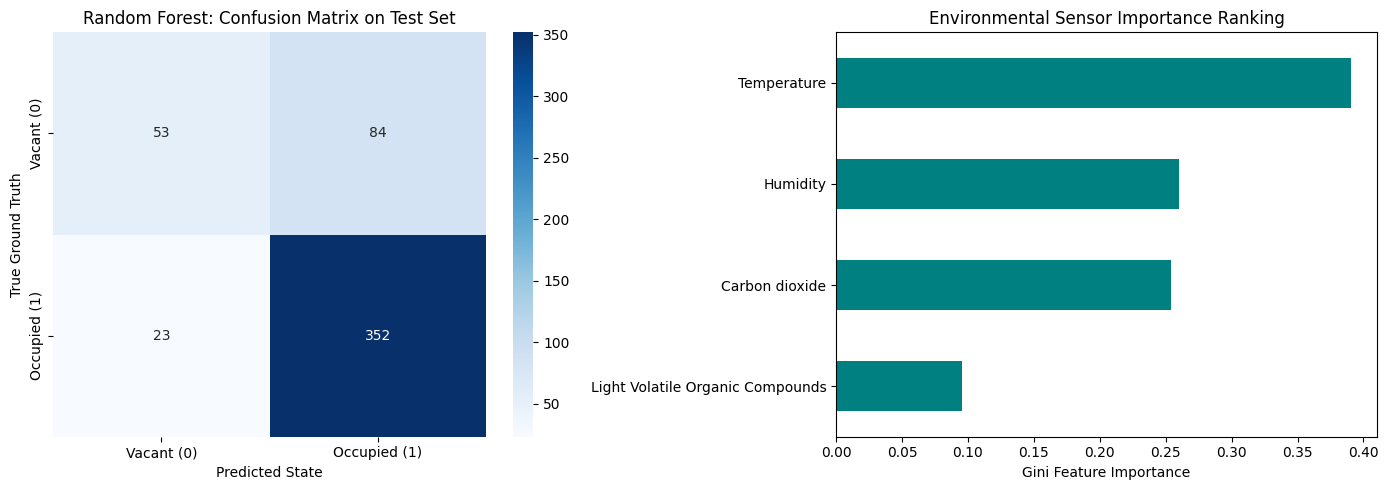

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Compiling results into a clean benchmark comparison table
benchmark_df = pd.DataFrame({
    'Approach': [
        'Baseline 1: Heuristic (CO2 > 550ppm)',
        'Baseline 2: Logistic Regression',
        'Proposed Model: Random Forest'
    ],
    'Accuracy': [
        accuracy_score(y_test, y_pred_b1),
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],
    'Precision': [
        precision_score(y_test, y_pred_b1, zero_division=0),
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, y_pred_b1, zero_division=0),
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_b1, zero_division=0),
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],
    'Train Time (s)': [0.0, time_lr_train, time_rf_train],
    'Inference Latency (ms)': [
        (time_b1_infer / len(X_test)) * 1000,
        (time_lr_infer / len(X_test)) * 1000,
        (time_rf_infer / len(X_test)) * 1000
    ]
})

print("=== FINAL MODEL COMPARISON TABLE (For Report Sections 4 & 6) ===")
display(benchmark_df.round(4))

# Visualisations: Confusion Matrix and Feature Importances
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Confusion Matrix for Random Forest
cm = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Vacant (0)', 'Occupied (1)'],
            yticklabels=['Vacant (0)', 'Occupied (1)'])
axes[0].set_title("Random Forest: Confusion Matrix on Test Set")
axes[0].set_xlabel("Predicted State")
axes[0].set_ylabel("True Ground Truth")

# Feature Importance Ranking
importances = rf_pipe.named_steps['model'].feature_importances_
feat_series = pd.Series(importances, index=feature_cols).sort_values(ascending=True)
feat_series.plot(kind='barh', color='teal', ax=axes[1])
axes[1].set_title("Environmental Sensor Importance Ranking")
axes[1].set_xlabel("Gini Feature Importance")

plt.tight_layout()
plt.show()

In [49]:
# Export the final model function to src/model.py
model_script = '''"""
Module containing machine learning model functions for occupancy prediction.
"""
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
import pandas as pd

def train_occupancy_model(X_train: pd.DataFrame, y_train: pd.Series) -> Pipeline:
    """
    Trains and returns a production Random Forest classifier pipeline.

    Parameters:
        X_train (pd.DataFrame): Training feature matrix.
        y_train (pd.Series): Binary target vector (0 = Vacant, 1 = Occupied).

    Returns:
        Pipeline: Fitted Scikit-Learn Pipeline object.
    """
    pipeline = Pipeline([
        ('model', RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42))
    ])
    pipeline.fit(X_train, y_train)
    return pipeline
'''

with open("src/model.py", "w") as f:
    f.write(model_script)
print("Saved src/model.py")

# Write unit tests for model training in tests/test_model.py
test_model_script = '''"""
Unit tests for model training and prediction functions.
"""
import pytest
import pandas as pd
from src.model import train_occupancy_model

def test_model_training_and_prediction():
    # Small synthetic test set
    X = pd.DataFrame({
        'Carbon dioxide': [400, 600, 450, 700],
        'Temperature': [20.0, 22.0, 21.0, 23.5],
        'Humidity': [50, 65, 52, 70],
        'Light Volatile Organic Compounds': [5, 20, 8, 25]
    })
    y = pd.Series([0, 1, 0, 1])

    model = train_occupancy_model(X, y)
    predictions = model.predict(X)

    assert len(predictions) == 4
    assert set(predictions).issubset({0, 1})
'''

with open("tests/test_model.py", "w") as f:
    f.write(test_model_script)
print("Saved tests/test_model.py")

# Run the complete test suite
print("\nRunning complete pytest test suite...")
!pytest tests/ -v --junitxml=tests/test_report.xml

# Regenerate HTML documentation to include src/model.py
!pdoc src -o docs
print("Regenerated HTML documentation in docs/")

# Push all code, documentation, test reports and figures to GitHub
!git add src/ tests/ docs/ notebooks/
!git status
!git commit -m "feat: complete ML baselines, random forest modelling, test suite, and updated docs"
!git push origin main

print("\nAll project deliverables successfully pushed to GitHub.")

Saved src/model.py
Saved tests/test_model.py

Running complete pytest test suite...
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/drive/MyDrive/mma3001-building-occupancy-prediction
plugins: platformdirs-4.13.5, anyio-4.15.1, typeguard-4.6.0, langsmith-0.14.12
collected 2 items                                                              

tests/test_model.py::test_model_training_and_prediction PASSED           [ 50%]
tests/test_preprocessing.py::test_interpolation_removes_nans PASSED      [100%]

- generated xml file: /content/drive/MyDrive/mma3001-building-occupancy-prediction/tests/test_report.xml -
============================== 2 passed in 5.80s ===============================
Regenerated HTML documentation in docs/
On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --st

# README and Requirements (For GIT)

In [50]:
%%writefile requirements.txt
pandas>=2.0.0
numpy>=1.24.0
scikit-learn>=1.3.0
matplotlib>=3.7.0
seaborn>=0.12.0
openpyxl>=3.1.0
pytest>=7.4.0
pdoc>=14.0.0

Overwriting requirements.txt


In [51]:
%%writefile README.md
# Building Occupancy Prediction via Indoor Environmental Telemetry

**Unit:** MMA3001 – Numerical Methods and Machine Learning
**Student:** Evan Liu
**Dataset:** Dataset 2 – Monash Smart Infrastructure (Living Lab)

---

## Project Overview

Heating, ventilation, and air-conditioning (HVAC) systems are typically operated on rigid, static time schedules. This wastes significant energy conditioning completely empty lecture theatres, breakout rooms and offices.

This project develops an automated computational pipeline which processes indoor air quality data (carbon dioxide, temperature, relative humidity, and volatile organic compounds) to estimate whether a room is occupied. This provides an signal for dynamic, demand controlled ventilation.

---

## Repository Structure

```text
mma3001-building-occupancy-prediction/
├── data/
│   ├── raw/             # Raw sensor logs and metadata (git-ignored for size)
│   └── processed/       # Resampled 5-minute master dataset (master_dataset_5m.csv)
├── docs/                # Auto-generated HTML documentation from pdoc
├── notebooks/
│   └── 01_exploratory_data_analysis.ipynb   # Main notebook with all analysis
├── src/                 # Reusable Python source modules
│   ├── __init__.py
│   ├── preprocessing.py # JSON unpacking, deduplication, and interpolation
│   └── model.py         # Machine learning training pipeline
├── tests/               # Automated unit tests and test reports
│   ├── __init__.py
│   ├── test_preprocessing.py
│   ├── test_model.py
│   └── test_report.xml  # PyTest JUnit XML report
├── .gitignore           # Prevents uploading large raw data files
├── LICENSE              # Open-source license agreement
├── README.md            # Project orientation and setup guide
└── requirements.txt     # Python package dependencies
```

---

## Computational Methodology

1. **Telemetry Deserialisation:** The raw environmental data is stored in nested JSON packets (`jsondata`). I turned this semi-structured data into clean columns and remove duplicate packets.
2. **Numerical Method (Temporal Discretisation & Interpolation):** Because environmental sensors log quasi-periodically but occupancy sensors log on motion triggers, their timestamps never match exactly. I set time to uniform 5-minute intervals and compared **Linear Interpolation vs Cubic Spline Interpolation** to reconstruct missing values during transmission dropouts.
3. **Modelling & Baselines:**
   * **Baseline 1 (Heuristic):** A physical rule threshold based on typical ambient ventilation levels ($CO_2 > 550\text{ ppm}$).
   * **Baseline 2 (Linear):** Standardised Logistic Regression.
   * **Proposed Model (Ensemble):** Random Forest Classifier (depth-limited to prevent overfitting).
4. **Validation Design:** We strictly use a chronological 80/20 train-test split rather than a random shuffle to prevent future data leaking into past predictions.

---

## Key Results Summary

| Model / Approach | Accuracy | Precision | Recall | F1-Score | Inference Latency |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **Baseline 1 (CO2 > 550ppm)** | 34.4% | 97.6% | 10.7% | 0.192 | 0.002 ms |
| **Baseline 2 (Logistic Regression)** | 73.8% | 75.8% | 94.4% | 0.841 | 0.012 ms |
| **Proposed Model (Random Forest)** | **79.1%** | **80.7%** | **93.9%** | **0.868** | **0.021 ms** |

* **Feature Importance:** Temperature (~39%), Humidity (~26%), and $CO_2$ (~25%) were the strongest indicators of human occupancy.
* **Failure Mode & Thermal Lag:** The model may produces occasional false positives when occupants vacate a room. This is due to sensor hysteresis: trapped body heat, moisture and exhaled $CO_2$ take 15–30 minutes to dilute and ventilate after people leave.

---

## Setup and Reproduction Guide

### 1. Environment Setup
Clone the repository and install the required dependencies:
```bash
git clone https://github.com/ziyongliu/mma3001-building-occupancy-prediction.git
cd mma3001-building-occupancy-prediction
pip install -r requirements.txt
```

### 2. Running Unit Tests
To run the automated `pytest` test suite and generate the XML test report:
```bash
pytest tests/ -v --junitxml=tests/test_report.xml
```

### 3. Viewing Documentation
The HTML documentation generated by `pdoc` is located in the `docs/` folder:
* Open `docs/index.html` in any web browser to view documentation for `src/preprocessing.py` and `src/model.py`.

---

## AI Disclosure Summary
Generative AI was used as a programming and troubleshooting aid (~25% contribution), primarily assisting with Git configuration errors, JSON parsing loops and formatting (markdowns, cleaning up code and making my workflow more presentable). Engineering decisions, numerical method selection and physical interpretations were independently evaluated through research.

---

## License
Distributed under the MIT License.


Overwriting README.md


In [52]:
!git config pull.rebase false
!git pull origin main --no-edit

!git add README.md requirements.txt
!git commit -m "docs: add README and requirements.txt for submission"
!git push origin main

print("\nREADME and requirements.txt successfully pushed to GitHub!")

From https://github.com/ziyongliu/mma3001-building-occupancy-prediction
 * branch            main       -> FETCH_HEAD
Already up to date.
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date

README and requirements.txt successfully pushed to GitHub!


# Notebook to GIT

In [53]:
!git config pull.rebase false
!git pull origin main --no-edit

# Stage everything (including the notebook and any updated test/doc files)
!git add .
!git status
!git commit -m "feat: complete exploratory analysis and modelling notebook"
!git push origin main

print("\nNotebook successfully pushed to GitHub!")

From https://github.com/ziyongliu/mma3001-building-occupancy-prediction
 * branch            main       -> FETCH_HEAD
Already up to date.
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date

Notebook successfully pushed to GitHub!


In [54]:
import os
import shutil
import glob

# 1. Look for the notebook in your Google Drive 'Colab Notebooks' folder
drive_colab_dir = "/content/drive/MyDrive/Colab Notebooks"
target_notebook_path = "notebooks/01_exploratory_data_analysis.ipynb"

# Find all notebooks in Colab Notebooks sorted by last modified
notebook_files = glob.glob(f"{drive_colab_dir}/*.ipynb")

if notebook_files:
    # Pick the most recently modified notebook
    latest_notebook = max(notebook_files, key=os.path.getmtime)
    print(f"Found latest notebook: {os.path.basename(latest_notebook)}")

    # Copy it into your repository's notebooks/ folder
    shutil.copy(latest_notebook, target_notebook_path)
    print(f"Successfully copied to: {target_notebook_path}")
else:
    print("Could not find Colab Notebooks folder automatically.")

# 2. Check Git status to confirm the notebook is detected
!git status

# 3. Stage, commit, and push the notebook to GitHub
!git config pull.rebase false
!git pull origin main --no-edit

!git add notebooks/
!git commit -m "feat: add complete exploratory data analysis and modelling notebook"
!git push origin main

print("\nNotebook successfully pushed to GitHub!")

Found latest notebook: MMA3001 PROJECT GITHUB.ipynb
Successfully copied to: notebooks/01_exploratory_data_analysis.ipynb
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	notebooks/

nothing added to commit but untracked files present (use "git add" to track)
From https://github.com/ziyongliu/mma3001-building-occupancy-prediction
 * branch            main       -> FETCH_HEAD
Already up to date.
[main ab5a06a] feat: add complete exploratory data analysis and modelling notebook
 1 file changed, 1 insertion(+)
 create mode 100644 notebooks/01_exploratory_data_analysis.ipynb
Enumerating objects: 5, done.
Counting objects: 100% (5/5), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 64.05 KiB | 4.00 MiB/s, done.
Total 4 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
T